## 3D Fiber Segmentation

### Objective:
Segment fibers in a 3D image from MicroCT scans using different methods of continuity such as the one used in 2D and based on Persistence Length.

In [3]:
# Librarys and functions

import os
import numpy as np
import pandas as pd
import tifffile
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from PIL import Image
from skimage.measure import label
from scipy.spatial import cKDTree
from skimage.morphology import remove_small_objects
from skimage.color import label2rgb, gray2rgb
from skimage.measure import label, regionprops
from skimage.morphology import skeletonize
from scipy.ndimage import binary_closing, binary_opening
from skimage.util import invert, img_as_float
from skan import Skeleton, summarize
from itertools import combinations
from scipy.ndimage import distance_transform_edt
from skimage.segmentation import watershed
from skimage.io import imread
from skimage import filters, restoration
from tqdm import tqdm
from IPython.display import clear_output
from skimage.filters import threshold_otsu

In [32]:
def binary_to_rgb(binary_img):
    mask = binary_img.astype(bool)
    rgb_img = np.zeros((*mask.shape, 3), dtype=np.uint8)
    rgb_img[mask] = (255, 0, 0)
    return rgb_img

def binary_to_gray(binary_img, fg=255, bg=0):
    return np.where(binary_img, fg, bg).astype(np.uint8)

def junction_mask_3d(skeleton_3d):
    sk = Skeleton(skeleton_3d)
    labels = np.zeros(skeleton_3d.shape, dtype=np.uint8)

    # Label all skeleton voxels as 1 (non-junction by default)
    labels[skeleton_3d] = 1

    # Label junction voxels as 2
    j_ids = np.where(sk.degrees >= 3)[0]
    if j_ids.size:
        coords = np.round(sk.coordinates[j_ids]).astype(int)  # (z,y,x)
        z = np.clip(coords[:, 0], 0, skeleton_3d.shape[0] - 1)
        y = np.clip(coords[:, 1], 0, skeleton_3d.shape[1] - 1)
        x = np.clip(coords[:, 2], 0, skeleton_3d.shape[2] - 1)
        labels[z, y, x] = 2

    return labels

def filter_skeleton(skeleton_3d_img, tam_min):
    print("------------FILTERING THE SKELETON----------")
    print("     - Removing branches with ", tam_min, " or less voxels.")
    # Copying the original skeleton and making the object
    _skeleton_3d = skeleton_3d_img.copy()
    skeleton_obj = Skeleton(_skeleton_3d)

    # Getting the skeleton information
    summary = summarize(skeleton_obj, separator='-')

    # Getting the junction points
    junction_points_ids = np.where(skeleton_obj.degrees >= 3)[0]

    print("     -", len(junction_points_ids), " junction points found.")

    n_rm = 0

    # Iterate througth the junction points
    for junction_id in junction_points_ids:

        # Get the branches connected to the jp
        connected_branches = summary[(summary['node-id-src'] == junction_id) | (summary['node-id-dst'] == junction_id)]

        # Erase the branches with less than 5 voxels
        for _, branch in connected_branches.iterrows():
            branch_voxels = skeleton_obj.path_coordinates(int(branch.name))
            branch_len = len(branch_voxels)

            if branch_len <= tam_min:
                n_rm = n_rm + 1
                z, y, x = branch_voxels[1:].T
                _skeleton_3d[z, y, x] = False
        
    print("     -", n_rm, " branches removed.")
    print("------------FILTERING ENDED----------\n\n")
    
    return _skeleton_3d

def dir_vec(junc, pt):
    junc = np.asarray(junc, float)
    pt   = np.asarray(pt,   float)
    v = pt - junc
    n = np.linalg.norm(v)
    return v / n if n > 0 else v

def best_straight_pair(vectors):
    V = np.vstack(vectors)             # (n,3) já normalizados
    cos = V @ V.T                      # cossenos
    np.fill_diagonal(cos, +np.inf)     # ignora diagonal
    i, j = np.unravel_index(np.argmin(cos), cos.shape)  # menor cos ~ -1 => ~180°
    ang = np.degrees(np.arccos(np.clip(cos[i, j], -1, 1)))
    return (i, j, ang)

def prune_skeleton(skeleton_3d_img, local_search, local_range):
    # Copying the original skeleton and making the object
    _skeleton_3d = skeleton_3d_img.copy()
    skeleton_obj = Skeleton(_skeleton_3d)

    # Getting the skeleton information
    summary = summarize(skeleton_obj, separator='-')

    # Getting the junction points
    junction_points_ids = np.where(skeleton_obj.degrees >= 3)[0]

    print(len(junction_points_ids), " junction points found.")

    # Iterate througth the junction points
    for junction_id in junction_points_ids:

        # Get the coordinates of the jp
        junction_coords = skeleton_obj.coordinates[junction_id]

        print("-> Analisando o ponto de junção {", junction_coords, "}")

        # Get the branches connected to the jp
        connected_branches = summary[(summary['node-id-src'] == junction_id) | (summary['node-id-dst'] == junction_id)]

        # Garantee minimum of three branches
        if len(connected_branches) < 3:
            continue

        vectors = []
        branches_ids = []
        for _, branch in connected_branches.iterrows():
            
            # Enter if local_search is 1, i.e., the decision is made based on the local continuity, not the global
            if local_search:
                branch_voxels = skeleton_obj.path_coordinates(int(branch.name))
                len_branch = len(branch_voxels)

                # Localize the start/end of the branch that end/start at the junction point

                if branch['node-id-src'] == junction_id:                                # Is the junction point the start of the branch?
                    if len_branch > local_range:                                        # Forces local analysis
                        other_coords = branch_voxels[local_range]                       # Get the coordinates of the voxel in the 
                                                                                        #   local distance as the endpoint
                    else:
                        other_node_id = branch['node-id-dst']                           # Get the endpoint
                        other_coords = skeleton_obj.coordinates[int(other_node_id)]     # Get the coordinates of the endpoint
                else:                                                                   # The junction point is the end of the branch
                    if len_branch > local_range:                                        # Forces local analysis
                        other_coords = branch_voxels[-(local_range-1)]                  # Get the coordinates of the voxel in the 
                                                                                        #   local distance as the startpoint
                    else:
                        other_node_id = branch['node-id-src']                           # Get the startpoint
                        other_coords = skeleton_obj.coordinates[int(other_node_id)]     # Get the coordinates of the startpoint
            else:
                other_node_id = branch['node-id-dst'] if branch['node-id-src'] == junction_id else branch['node-id-src']
                junc_is_src = 1 if branch['node-id-src'] == junction_id else 0
                other_coords = skeleton_obj.coordinates[int(other_node_id)]

            vectors.append(dir_vec(junction_coords, other_coords))
            branches_ids.append(int(branch.name))
        
        i, j, ang = best_straight_pair(vectors)

        print("     Ramos observados: ", branches_ids)
        print("     Ramos escolhidos: {", branches_ids[i], branches_ids[j], "} com ângulo de ", round(ang, 2))

        branch_to_prune = int(np.delete(branches_ids, [i,j])[0])

        branch_to_prune_voxels = skeleton_obj.path_coordinates(branch_to_prune)

        if np.array_equal(branch_to_prune_voxels[0], junction_coords):
            coords_to_set_zero = tuple(branch_to_prune_voxels[1])
        else:
            coords_to_set_zero = tuple(branch_to_prune_voxels[-2])
        
        print("     Podando ramo {", branch_to_prune, "} na coordenada {", coords_to_set_zero, "} \n\n")

        _skeleton_3d[coords_to_set_zero] = 0
    
    return _skeleton_3d

def label_fibers_watershed(binary, markers):
    """
    Aplica distância euclidiana 3D e Watershed para propagar rótulos do esqueleto.
    Parâmetros:
      - binary: volume binário (bool ou 0/1)
      - markers: volume de marcadores inteiros (mesmo shape de binary)
    Retorna:
      - fibras_rotuladas: rótulos propagados pelo Watershed
      - distancia: distância euclidiana 3D do binário
    """
    binary = binary.astype(bool)
    if binary.shape != markers.shape:
        raise ValueError("binary e markers devem ter o mesmo shape.")

    distancia = distance_transform_edt(binary)
    fibras_rotuladas = watershed(-distancia, markers=markers, mask=binary)
    return fibras_rotuladas

In [5]:
# Importing imagem
# Image options:
#   "./fiber_img/data/PPGF40.tif"
#   "./fiber_img/data/PPGF40HNT0-1.0.tif"
#   "./fiber_img/data/PPGF40HNT0-1.5.tif"
#   "./fiber_img/data/PPGF40HNT0-5.tif"

filename = "./fiber_img/data/PPGF40HNT0-1.0.tif"
raw_tiff_img = tifffile.imread(filename)

# Converting to 8bits gray scale
raw_tiff_img = (raw_tiff_img / np.max(raw_tiff_img) * 255).astype(np.uint8)

Selected image:  ./fiber_img/data/PPGF40HNT0-1.0.tif
Dimensions raw image:  
 X:  1649  
 Y:  1055  
 Z:  658
Dimensions selected image (no shadows):   
 X:  1649  
 Y:  815  
 Z:  405


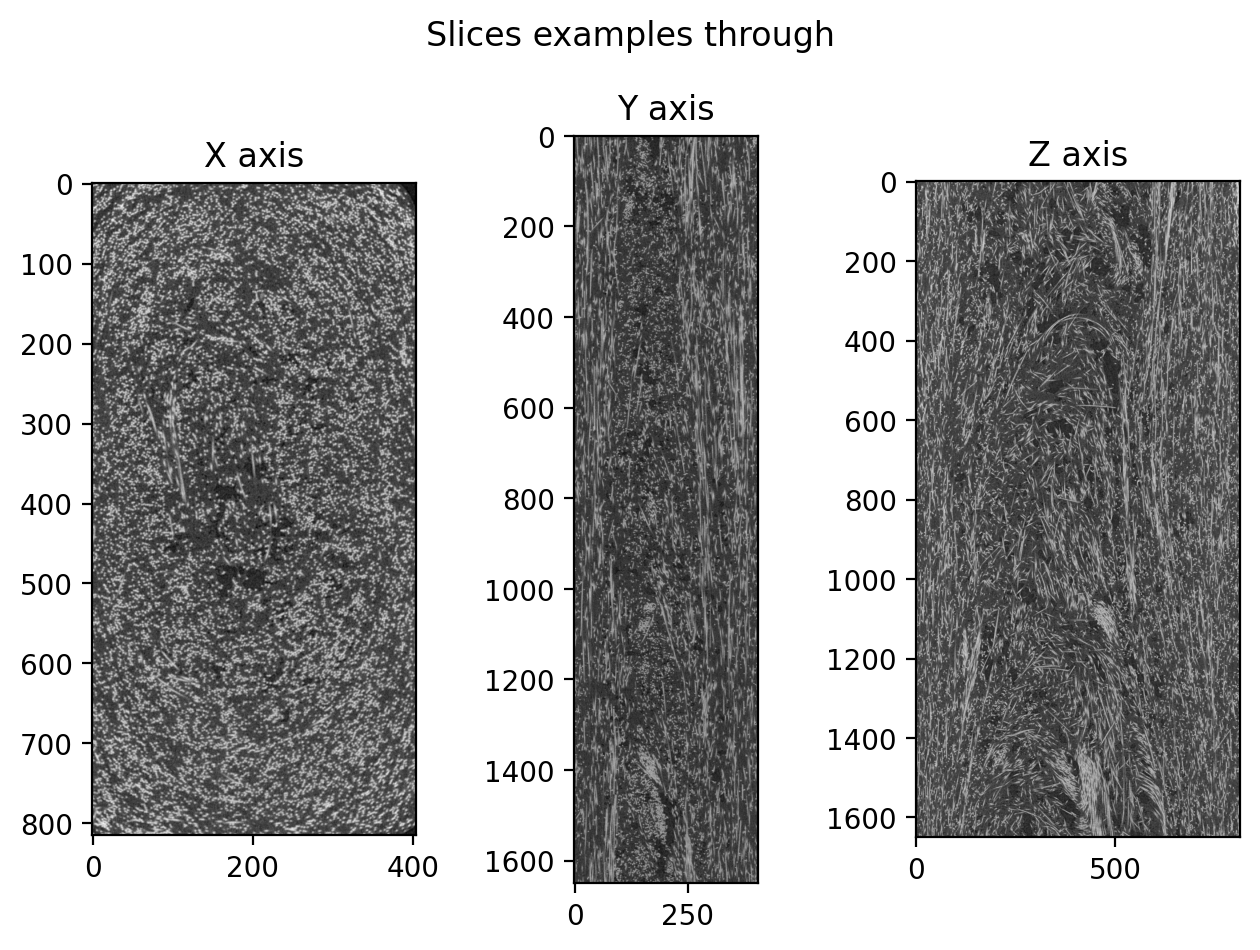

In [6]:
# Details of the image
print("Selected image: ", filename)
print("Dimensions raw image:",
      " \n X: ", raw_tiff_img.shape[0], 
      " \n Y: ", raw_tiff_img.shape[1], 
      " \n Z: ", raw_tiff_img.shape[2])

# Selecting only the slices with no shadows
if filename == "./fiber_img/data/PPGF40HNT0-1.0.tif":
    selected_tiff_img = raw_tiff_img[:, 125:940, 130:535]

print("Dimensions selected image (no shadows): ",
      " \n X: ", selected_tiff_img.shape[0], 
      " \n Y: ", selected_tiff_img.shape[1], 
      " \n Z: ", selected_tiff_img.shape[2])

# Axis plot
plt.figure(dpi=200)
plt.suptitle("Slices examples through")
plt.subplot(1,3,1)
plt.imshow(selected_tiff_img[500,:,:], cmap='gray')
plt.title("X axis")

plt.subplot(1,3,2)
plt.imshow(selected_tiff_img[:,400,:], cmap='gray')
plt.title("Y axis")

plt.subplot(1,3,3)
plt.imshow(selected_tiff_img[:,:,200], cmap='gray')
plt.title("Z axis")

plt.tight_layout()
plt.show()

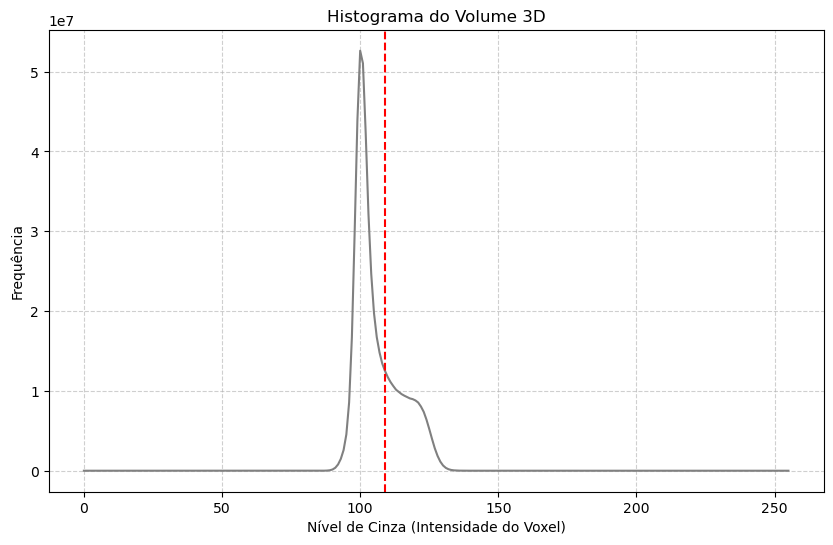

In [7]:
# Image binarization

# Choosing threshold with Otsu criterium
binary_threshold = threshold_otsu(selected_tiff_img)

# Verifying the chosen threshold looking at the voxels intensity distributions
histogram_intensity, bins = np.histogram(selected_tiff_img.ravel(), bins=256, range=(0, 256))

plt.figure(figsize=(10, 6))
plt.title("Histograma do Volume 3D")
plt.xlabel("Nível de Cinza (Intensidade do Voxel)")
plt.ylabel("Frequência")
plt.plot(histogram_intensity, color='gray')
plt.grid(True, linestyle='--', alpha=0.6)
plt.axvline(x=binary_threshold, color='r', linestyle='--')
plt.show()

binary_img = selected_tiff_img > binary_threshold

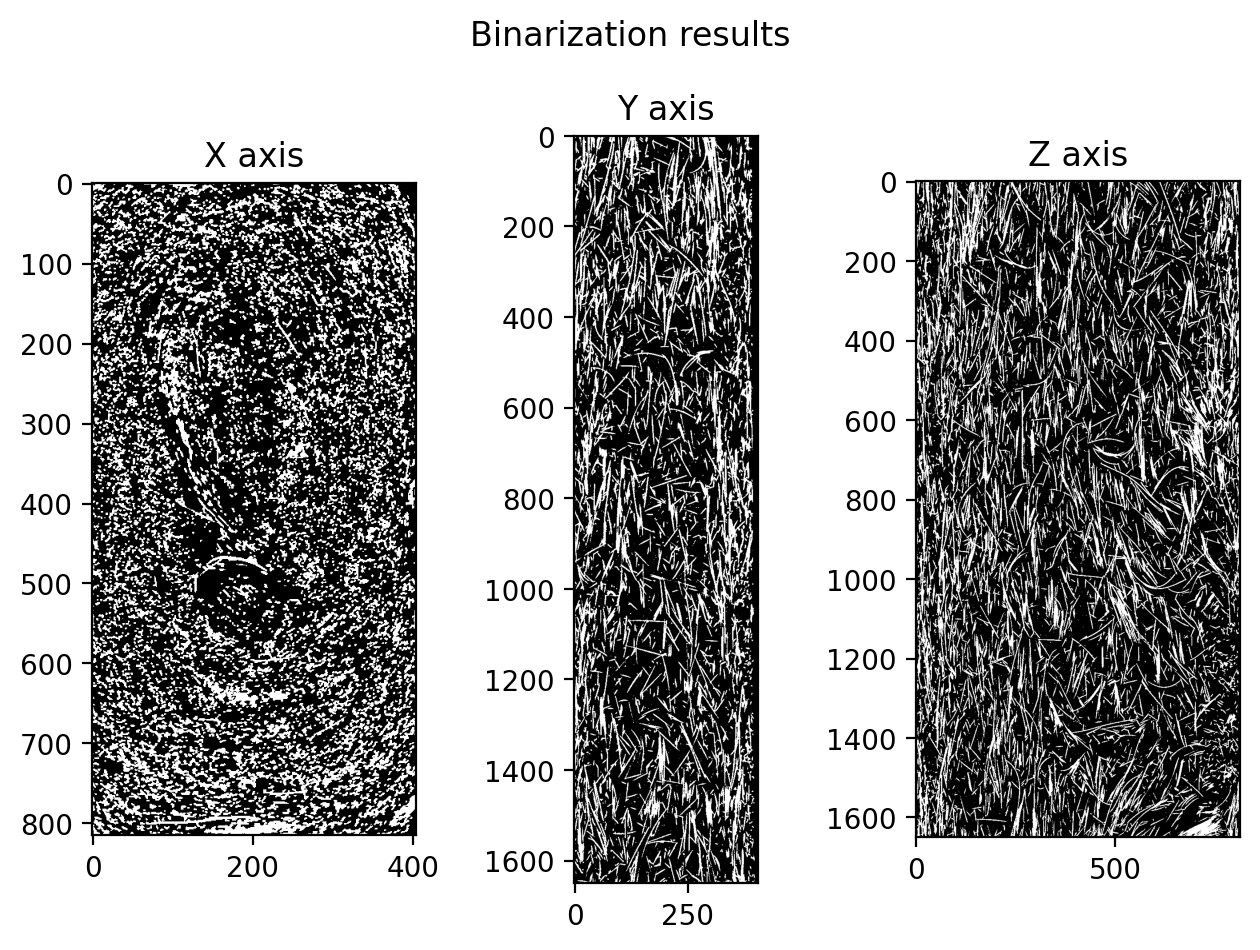

In [8]:
# Binarization results

# Axis plot
plt.figure(dpi=200)
plt.suptitle("Binarization results")
plt.subplot(1,3,1)
plt.imshow(binary_img[10,:,:], cmap='gray')
plt.title("X axis")

plt.subplot(1,3,2)
plt.imshow(binary_img[:,10,:], cmap='gray')
plt.title("Y axis")

plt.subplot(1,3,3)
plt.imshow(binary_img[:,:,10], cmap='gray')
plt.title("Z axis")

plt.tight_layout()
plt.show()

# Visualizing w/ Napari
# tifffile.imwrite("./fiber_img/3d-res/binary_img.tif", binary_img.astype(np.uint8) * 255)
# scp homero_castro@litc59:/home/homero_castro/toronto/fiber_img/3d-res/binary_img.tif C:\Users\Homero\documents\LITC\Toronto_Fibers\fiber_img\3d-res
# napari ./fiber_img/3d-res/binary_img.tif

In [9]:
# Selecting a 3D cubic section of the block for tests
n_pixels = 50

mean_X = round(selected_tiff_img.shape[0]/2)
mean_Y = round(selected_tiff_img.shape[1]/2)
mean_Z = round(selected_tiff_img.shape[2]/2)

n_pixels_each_side = round(n_pixels/2)

binary_cropped = binary_img[mean_X-n_pixels_each_side:mean_X+n_pixels_each_side,
                                mean_Y-n_pixels_each_side:mean_Y+n_pixels_each_side,
                                mean_Z-n_pixels_each_side:mean_Z+n_pixels_each_side]

# Visualizing w/ Napari
# tifffile.imwrite("./fiber_img/3d-res/binary_cropped.tif", binary_cropped.astype(np.uint8) * 255)
# scp homero_castro@litc59:/home/homero_castro/toronto/fiber_img/3d-res/binary_cropped.tif C:\Users\Homero\documents\LITC\Toronto_Fibers\fiber_img\3d-res
# napari ./fiber_img/3d-res/binary_cropped.tif

In [10]:
# skeleton_img = skeletonize(binary_img)

# Visualizing w/ Napari
# tifffile.imwrite("./fiber_img/3d-res/skeleton_img.tif", skeleton_img.astype(np.uint8) * 255)
# scp homero_castro@litc59:/home/homero_castro/toronto/fiber_img/3d-res/skeleton_img.tif C:\Users\Homero\documents\LITC\Toronto_Fibers\fiber_img\3d-res
# napari ./fiber_img/3d-res/skeleton_img.tif

In [11]:
skeleton_cropped = skeletonize(binary_cropped, method='lee')

# Visualizing w/ Napari
tifffile.imwrite("./fiber_img/3d-res/skeleton_cropped.tif", skeleton_cropped.astype(np.uint8) * 255)
# scp homero_castro@litc59:/home/homero_castro/toronto/fiber_img/3d-res/skeleton_cropped.tif C:\Users\Homero\documents\LITC\Toronto_Fibers\fiber_img\3d-res
# napari ./fiber_img/3d-res/skeleton_cropped.tif

In [12]:
labeled_cropped = label(skeleton_cropped)

tifffile.imwrite("./fiber_img/3d-res/labeled_cropped.tif", labeled_cropped.astype(np.uint8) * 255)
# scp homero_castro@litc59:/home/homero_castro/toronto/fiber_img/3d-res/labeled_cropped.tif C:\Users\Homero\documents\LITC\Toronto_Fibers\fiber_img\3d-res
# napari ./fiber_img/3d-res/labeled_cropped.tif --layer-type labels

In [13]:
filtered_skeleton = filter_skeleton(skeleton_cropped, 5)

tifffile.imwrite("./fiber_img/3d-res/filtered_skeleton.tif", filtered_skeleton.astype(np.uint8) * 255)
# scp homero_castro@litc59:/home/homero_castro/toronto/fiber_img/3d-res/filtered_skeleton.tif C:\Users\Homero\documents\LITC\Toronto_Fibers\fiber_img\3d-res
# napari ./fiber_img/3d-res/filtered_skeleton.tif

marked_skeleton = junction_mask_3d(filtered_skeleton)

tifffile.imwrite("./fiber_img/3d-res/marked_skeleton.tif", marked_skeleton.astype(np.uint8) * 255)
# scp homero_castro@litc59:/home/homero_castro/toronto/fiber_img/3d-res/marked_skeleton.tif C:\Users\Homero\documents\LITC\Toronto_Fibers\fiber_img\3d-res
# napari ./fiber_img/3d-res/marked_skeleton.tif --layer-type labels

------------FILTERING THE SKELETON----------
     - Removing branches with  5  or less voxels.
     - 632  junction points found.
     - 1494  branches removed.
------------FILTERING ENDED----------




In [27]:
prunned_skeleton = prune_skeleton(filtered_skeleton, True, 10)

prunned_skeleton = remove_small_objects(prunned_skeleton, min_size=5)

32  junction points found.
-> Analisando o ponto de junção { [ 2  8 18] }
     Ramos observados:  [3, 28, 29]
     Ramos escolhidos: { 3 28 } com ângulo de  140.77
     Podando ramo { 29 } na coordenada { (np.int64(2), np.int64(9), np.int64(17)) } 


-> Analisando o ponto de junção { [ 2  9 17] }
     Ramos observados:  [28, 29, 30]
     Ramos escolhidos: { 28 30 } com ângulo de  156.8
     Podando ramo { 29 } na coordenada { (np.int64(2), np.int64(8), np.int64(18)) } 


-> Analisando o ponto de junção { [ 3 26 45] }
     Ramos observados:  [10, 33, 34]
     Ramos escolhidos: { 10 33 } com ângulo de  147.0
     Podando ramo { 34 } na coordenada { (np.int64(4), np.int64(27), np.int64(46)) } 


-> Analisando o ponto de junção { [ 3 34 24] }
     Ramos observados:  [13, 14, 35]
     Ramos escolhidos: { 13 35 } com ângulo de  131.24
     Podando ramo { 14 } na coordenada { (np.int64(2), np.int64(35), np.int64(24)) } 


-> Analisando o ponto de junção { [10  5 46] }
     Ramos observados:  

In [ ]:
labeled_skeleton = label(prunned_skeleton)

tifffile.imwrite("./fiber_img/3d-res/labeled_skeleton.tif", labeled_skeleton.astype(np.uint8) * 255)
# scp homero_castro@litc59:/home/homero_castro/toronto/fiber_img/3d-res/labeled_skeleton.tif C:\Users\Homero\documents\LITC\Toronto_Fibers\fiber_img\3d-res
# napari ./fiber_img/3d-res/labeled_skeleton.tif --layer-type labels

In [ ]:
labeled_fibers = label_fibers_watershed(binary_cropped, labeled_skeleton)

tifffile.imwrite("./fiber_img/3d-res/labeled_fibers.tif", labeled_fibers.astype(np.uint8) * 255)
# scp homero_castro@litc59:/home/homero_castro/toronto/fiber_img/3d-res/labeled_fibers.tif C:\Users\Homero\documents\LITC\Toronto_Fibers\fiber_img\3d-res
# napari ./fiber_img/3d-res/labeled_fibers.tif --layer-type labels